#  Can an order book snapshot predict a profitable short trade?

This notebook runs the whole project step by step so you can see what each part does.

> **Note:** it uses *synthetic* data so it runs in seconds with no download. The synthetic book has a weak
> imbalance signal planted in it on purpose, so the scores below only show that the pipeline works -
> they are **not** a result on real markets. For real data, see the commented line in step 1.

In [1]:
import sys
sys.path.insert(0, "../src")   # lets the notebook import the package without installing it

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lobtrade.data import clean_book, load_book
from lobtrade.synthetic import generate_synthetic_book
from lobtrade.labeling import compute_labels
from lobtrade.features import build_features
from lobtrade.model import make_dataset, chronological_split, train_model, evaluate

## 1. Load and clean the data
Each row is one snapshot of the limit order book (15 price levels on the bid side and 15 on the ask side).

In [3]:
# Real data (download the Kaggle zip first):
# book = clean_book(load_book("high-frequency-crypto-limit-order-book-data.zip", member="BTC_1sec.csv", nrows=200_000))

book = clean_book(generate_synthetic_book(n=6000, seed=0))
print(book.shape)
book[["system_time", "midpoint", "spread", "bids_notional_0", "asks_notional_0"]].head()

(5999, 155)


,system_time,midpoint,spread,bids_notional_0,asks_notional_0
0,2021-04-07 11:32:43+00:00,49998.128860,0.01,1018.305121,1775.912628
1,2021-04-07 11:32:44+00:00,49971.476862,0.01,2099.638804,1674.700730
2,2021-04-07 11:32:45+00:00,49958.204320,0.01,2760.426087,2906.782472
3,2021-04-07 11:32:46+00:00,49958.459842,0.01,2822.011410,2752.471856
4,2021-04-07 11:32:47+00:00,49978.185447,0.01,1660.741023,2403.317643


## 2. Label each row
At every row we pretend to **buy** at market, then **sell** 5 rows (5 seconds) later, and pay a fee on both trades.
A buy walks up the ask side of the book and a sell walks down the bid side, so bigger orders get worse prices.

`net_return = (sell price - buy price) / buy price - 2 * fee`  
`profitable = net_return > 0`

In [5]:
FEE = 0.0001      
HORIZON = 5       # hold for 5 seconds
labels = compute_labels(book, trade_notional=1000, horizon=HORIZON, fee_rate=FEE)
labels.dropna().head()

,buy_price,sell_price,gross_return,net_return,profitable
0,49998.133860,50010.736902,0.000252,0.000052,True
1,49971.481859,50019.481998,0.000961,0.000761,True
2,49958.209316,50001.169067,0.000860,0.000660,True
3,49958.464837,49994.662132,0.000725,0.000525,True
4,49978.190444,50008.973670,0.000616,0.000416,True


share of profitable trades: 0.438


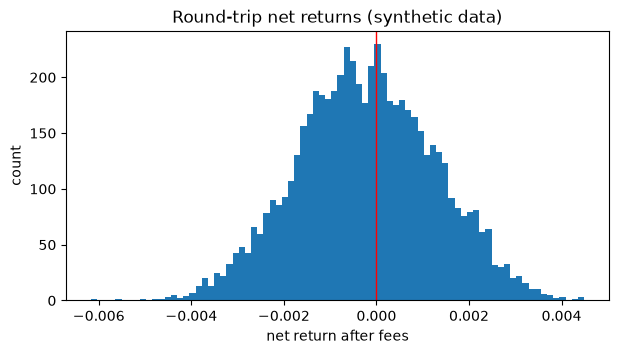

In [6]:
print("share of profitable trades:", round(labels["profitable"].dropna().astype(float).mean(), 3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(labels["net_return"].dropna(), bins=80)
ax.axvline(0, color="red", lw=1)
ax.set_xlabel("net return after fees"); ax.set_ylabel("count")
ax.set_title("Round-trip net returns (synthetic data)")
plt.show()

## 3. Feature engineering
Everything is computed only from the current and *past* rows, never the future, so the model can't cheat.
(`tests/test_features_model.py` checks this by changing future rows and confirming past features don't move.)

Feature groups: spread, past returns, rolling volatility, order book imbalance, depth, and order flow.

In [8]:
X = build_features(book)
print(X.shape)
X.dropna().describe().T[["mean", "std", "min", "max"]].round(4).head(12)

(5999, 28)


,mean,std,min,max
spread_rel,0.0000,0.0000,0.0000,0.0000
ret_1s,-0.0000,0.0005,-0.0018,0.0016
ret_5s,-0.0000,0.0015,-0.0060,0.0047
ret_30s,-0.0001,0.0067,-0.0189,0.0163
ret_60s,-0.0003,0.0115,-0.0289,0.0282
vol_30s,0.0004,0.0001,0.0002,0.0007
vol_60s,0.0004,0.0000,0.0003,0.0007
imbalance_1,-0.0122,0.4534,-0.9783,0.9702
log_depth_bid_1,7.3662,0.6759,4.2527,9.5746
log_depth_ask_1,7.3931,0.6845,4.2691,9.2038


## 4. Split by time, train, evaluate
Time series must be split in order (not shuffled). 60% train, 20% validation (to pick the trade threshold),
20% test (only looked at once). A gap of `horizon` rows between segments stops labels that overlap in time from leaking.

In [6]:
ds = make_dataset(book, trade_notional=1000, horizon=HORIZON, fee_rate=FEE)
tr, va, te = chronological_split(len(ds.y), gap=HORIZON)
print("train / val / test rows:", tr.stop - tr.start, va.stop - va.start, te.stop - te.start)

model = train_model(ds.X.iloc[tr], ds.y.iloc[tr])
metrics = evaluate(model, ds, HORIZON)
pd.Series({k: v for k, v in metrics.items() if not isinstance(v, dict)})

train / val / test rows: 3560 1182 1182


test_rows                 1182.000000
test_base_rate               0.443316
test_roc_auc                 0.828012
test_average_precision       0.803174
threshold                    0.979257
dtype: float64

In [7]:
pd.DataFrame({"model strategy": metrics["strategy"], "always trade": metrics["baseline_always_trade"]})

,model strategy,always trade
n_trades,6.000000,237.000000
mean_net_return,0.001945,-0.000173
hit_rate,1.000000,0.421941
total_net_return,0.011672,-0.041117


## 5. How to read this
- **ROC AUC / average precision** say whether the model ranks profitable trades above unprofitable ones (0.5 AUC = random).
- The **strategy** only trades when the score is very high; the **baseline** trades every time and loses money to fees.
- On this synthetic data the model beats the baseline, but that is expected because the signal was put there deliberately.
- On the real BTC data only ~0.035% of 5-second round trips were profitable with a 0.1% fee per side,
  so the real problem is much harder. See the readme file for details and next steps.